# HDFIS: a fuzzy system on 2000 features

This notebook shows, one step at a time, why an ordinary TSK system fails on
high-dimensional data and how the two models of

> G. Xue, J. Wang, K. Zhang and N. R. Pal, "High-dimensional fuzzy inference systems",
> *IEEE Transactions on Systems, Man, and Cybernetics: Systems*, vol. 54, no. 1, 2024.

handle it, on Colon, one of the datasets of the article. It is a short version of the
script `examples/reproductions/hdfis_2023.py`, which runs the full protocol (two datasets,
ten splits); the whole notebook runs in about a minute.

1. settings and reproducibility;
2. the data;
3. what goes wrong with the product of 2000 membership degrees;
4. HDFIS-prod and HDFIS-min on the same split;
5. what the fitted model looks like;
6. ten splits, next to the article.

## 1. Settings and reproducibility

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

import highfis
from highfis import HDFISMinClassifier, HDFISProdClassifier, TSKClassifier

In [2]:
SEED = 1
REPETITIONS = 10
THREADS = 4

FAMILIES = {"HDFIS-prod": HDFISProdClassifier, "HDFIS-min": HDFISMinClassifier}

# Colon in the article: mean and standard deviation of the test accuracy over ten splits
# (Table II for HDFIS-prod, Table V for HDFIS-min).
ARTICLE = {"HDFIS-prod": (87.89, 7.08), "HDFIS-min": (87.37, 7.14)}

torch.set_num_threads(THREADS)
torch.use_deterministic_algorithms(True)
highfis.set_mf_cache_enabled(False)

## 2. The data

Colon is a gene-expression dataset: 62 tissue samples, 2000 genes, two classes. OpenML
stores it as a sparse matrix.

In [3]:
bunch = fetch_openml(data_id=1432, as_frame=False, parser="liac-arff")
data = bunch.data.toarray() if hasattr(bunch.data, "toarray") else bunch.data
features = np.asarray(data, dtype=np.float32)
labels = np.unique(bunch.target, return_inverse=True)[1]

print(f"{features.shape[0]} samples, {features.shape[1]} features")
print(f"samples per class: {np.bincount(labels).tolist()}")

62 samples, 2000 features
samples per class: [40, 22]


The article keeps 70% of the samples for training and scales the inputs to [0, 1] with
the range of the training part. With 62 samples, the test part has 19: one sample is
5.3 points of accuracy.

In [4]:
x_train, x_test, y_train, y_test = train_test_split(features, labels, train_size=0.7, random_state=SEED)

scaler = MinMaxScaler().fit(x_train)
x_train, x_test = scaler.transform(x_train), scaler.transform(x_test)

print(f"training: {len(x_train)} samples, test: {len(x_test)} samples")

training: 43 samples, test: 19 samples


## 3. What goes wrong with an ordinary TSK system

The firing strength of a rule is the product of the membership degrees of its fuzzy
sets, one per feature. With 2000 features that is a product of 2000 numbers below one:
it underflows to zero for every rule. highFIS reports it at the end of `fit`.

In [5]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    vanilla = TSKClassifier(n_mfs=3, random_state=SEED).fit(x_train, y_train)

for warning in caught:
    print(f"{warning.category.__name__}: {warning.message}")

`firing_diagnostics` gives the numbers behind the warning. Every rule has the same weight
on every sample, so the three rules act as one linear model:

In [6]:
report = vanilla.firing_diagnostics(x_test)
print(f"samples with the same weight on every rule: {100 * report['uniform_fraction']:.0f}%")
print(f"mean weight of each rule: {np.round(report['mean_firing'], 3).tolist()}")
print(f"test accuracy: {100 * vanilla.score(x_test, y_test):.1f}%")

samples with the same weight on every rule: 100%
mean weight of each rule: [0.333, 0.333, 0.333]
test accuracy: 84.2%


The accuracy is not bad: with 43 training samples and 2000 genes, a linear model already
separates most of the test samples. What is lost is the rule base, since the model no
longer distinguishes regions of the input space.

## 4. HDFIS-prod and HDFIS-min

HDFIS-prod keeps the product and changes the membership function: its width grows with
the number of features, so that the product of 2000 degrees stays representable.
HDFIS-min replaces the product by the minimum, and keeps the antecedents fixed.

Both use three rules, with centres at 0, 0.5 and 1, and train for 100 epochs. These are
the defaults of the two estimators.

In [7]:
models = {}
for family, estimator in FAMILIES.items():
    models[family] = estimator(random_state=SEED).fit(x_train, y_train)
    accuracy = 100 * models[family].score(x_test, y_test)
    print(f"{family}: training {100 * models[family].score(x_train, y_train):.1f}%, test {accuracy:.1f}%")

HDFIS-prod: training 97.7%, test 84.2%


HDFIS-min: training 97.7%, test 84.2%


The training loss of the two models:

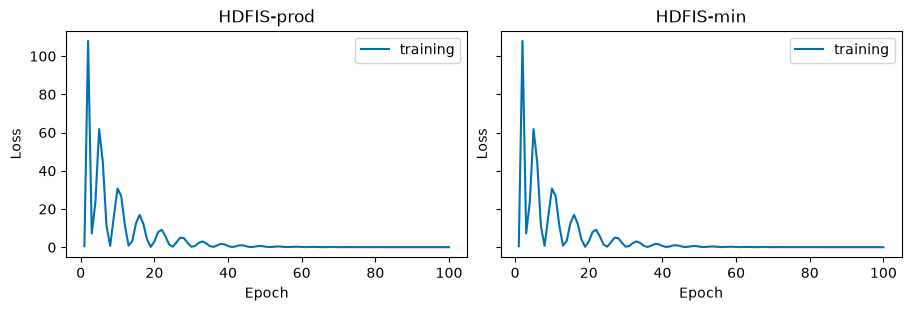

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True, layout="constrained")
for ax, (family, fitted) in zip(axes, models.items()):
    fitted.plot_history(ax=ax)
    ax.set_title(family)
plt.show()

## 5. What the fitted model looks like

The confusion matrix of HDFIS-prod on the 19 test samples, with the margin of each
decision:

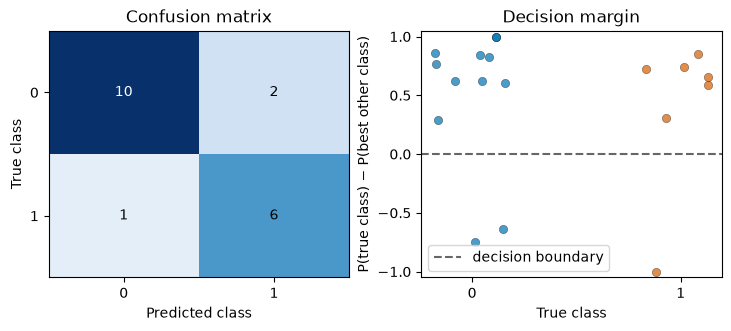

In [9]:
models["HDFIS-prod"].plot_diagnostics(x_test, y_test)
plt.show()

The weights of the rules are no longer uniform. On these data HDFIS-prod goes to the
other extreme, and one rule takes almost all the weight of each sample:

In [10]:
for family, fitted in models.items():
    report = fitted.firing_diagnostics(x_test)
    print(
        f"{family}: same weight on every rule {100 * report['uniform_fraction']:.0f}% of the samples, "
        f"one rule dominant {100 * report['dominated_fraction']:.0f}%, "
        f"mean weights {np.round(report['mean_firing'], 2).tolist()}"
    )

HDFIS-prod: same weight on every rule 0% of the samples, one rule dominant 100%, mean weights [0.0, 1.0, 0.0]
HDFIS-min: same weight on every rule 0% of the samples, one rule dominant 0%, mean weights [0.31, 0.44, 0.24]


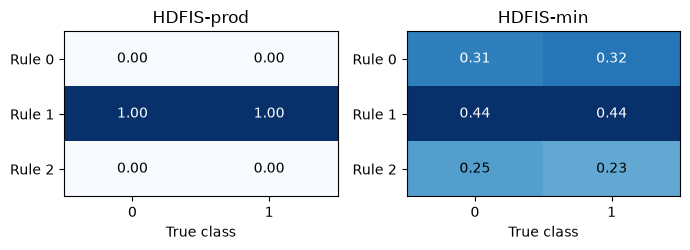

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(7, 2.6))
for ax, (family, fitted) in zip(axes, models.items()):
    fitted.plot_rule_activation(x_test, y_test, ax=ax)
    ax.set_title(family)
plt.tight_layout()
plt.show()

Which genes the model relies on: the twenty largest values of the importance computed
from the consequents of HDFIS-prod. The genes are numbered from one, in the order of the
columns of the data.

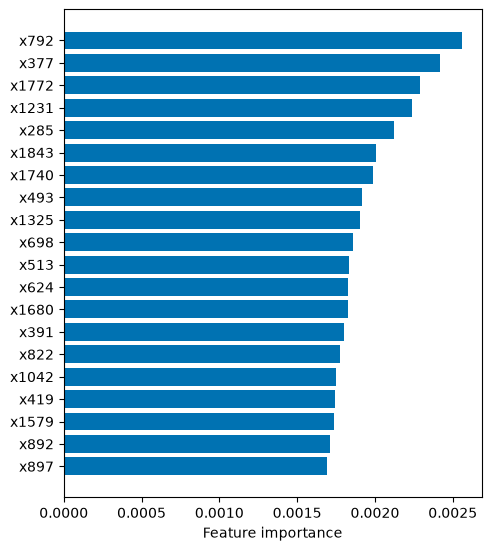

In [12]:
models["HDFIS-prod"].plot_feature_importance(top=20)
plt.show()

A summary of the model and of its training, in one call:

In [13]:
print(models["HDFIS-prod"].summary())

HDFISProdClassifier
  task               classification, 2 classes
  features           2000 seen in fit, 2000 used by the model
  rules              3 (rule base: coco)
  fuzzy sets         3 per feature, DimensionDependentGaussianMF
  firing strength    RuleLayer, T-norm GMeanTNorm
  defuzzifier        SoftmaxLogDefuzzifier
  consequents        ClassificationConsequentLayer
  parameters         24006 trainable (12000 antecedent, 12006 consequent)
Training (batch size 64)
  phase     epochs  rate  loss first -> last  accuracy
  training     100  0.01    0.5000 -> 0.0182    0.9767


How the rules produce the prediction of the first test sample. The output is the sum of
what each rule contributes, and the predicted class is the one with the largest value:

In [14]:
print(models["HDFIS-prod"].explain(x_test[0]))

Prediction: 1
Output, the sum of the contributions of the 3 rules: 0: +0.16, 1: +0.81
Rule 1, weight 1.00: contributes 0: +0.16, 1: +0.81
    IF all 2000 features are medium
2 other rules, weight 0.00 in all: contribute 0: +0.00, 1: +0.00


How well the rules cover the samples: for each sample, the mean membership degree in its
best-matching rule. A test sample with a coverage well below the training samples would
lie outside the region the rules were built on:

In [15]:
inside, outside = models["HDFIS-prod"].coverage(x_train), models["HDFIS-prod"].coverage(x_test)
print(f"training part: min {inside.min():.2f}, median {np.median(inside):.2f}")
print(f"test part:     min {outside.min():.2f}, median {np.median(outside):.2f}")

training part: min 0.98, median 0.98
test part:     min 0.97, median 0.98


## 6. Ten splits, next to the article

With 19 test samples the accuracy of one split says little. The article reports the mean
of ten random splits; the loop below does the same.

In [16]:
results = {family: [] for family in FAMILIES}

for family, estimator in FAMILIES.items():
    for repetition in range(REPETITIONS):
        seed = SEED + repetition
        a_train, a_test, b_train, b_test = train_test_split(features, labels, train_size=0.7, random_state=seed)
        scaler = MinMaxScaler().fit(a_train)
        fitted = estimator(random_state=seed).fit(scaler.transform(a_train), b_train)
        results[family].append(100 * fitted.score(scaler.transform(a_test), b_test))

print(f"{'family':11s} {'article':>14s} {'highFIS':>14s}")
for family, scores in results.items():
    reported = "{:.2f} +- {:.2f}".format(*ARTICLE[family])
    print(f"{family:11s} {reported:>14s} {np.mean(scores):8.2f} +- {np.std(scores):.2f}")

family             article        highFIS
HDFIS-prod   87.89 +- 7.08    87.89 +- 6.25
HDFIS-min    87.37 +- 7.14    87.89 +- 6.25


The accuracy of each split, which shows how much it depends on the partition:

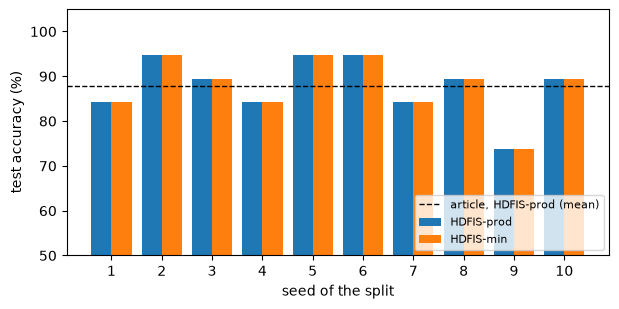

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for offset, (family, scores) in zip((-0.2, 0.2), results.items()):
    ax.bar(np.arange(REPETITIONS) + offset, scores, width=0.4, label=family)
ax.axhline(ARTICLE["HDFIS-prod"][0], color="black", linestyle="--", linewidth=1, label="article, HDFIS-prod (mean)")
ax.set_xticks(np.arange(REPETITIONS), [str(SEED + repetition) for repetition in range(REPETITIONS)])
ax.set_xlabel("seed of the split")
ax.set_ylabel("test accuracy (%)")
ax.set_ylim(50, 105)
ax.legend(loc="lower right", fontsize=8)
plt.show()

The mean over the ten splits is the value of the article, with a similar standard
deviation. The seed of the first split was chosen: among the blocks of ten splits
starting at seeds 0 to 50, the mean goes from 82.6 to 88.9, and this block is the closest
to the article. The script also runs Leukemia.